# Emotion Classification with a Fine-tuned Transformer (DistilBERT)

The third model family: a **pre-trained transformer** fine-tuned on our data. Unlike TF-IDF or an LSTM trained from scratch, DistilBERT has already learned English from a huge text corpus, so it understands context, negation and word meaning before seeing a single emotion label.

**Why DistilBERT?** It keeps about 97% of BERT's language understanding while being 40% smaller and 60% faster, which matters for a real-time voice app.

**Setup**
- model: `distilbert-base-uncased` (our text is lower case)
- train on train split, validation split for choosing the best epoch, test split once at the end
- max length 64 tokens (Phase 1 found 99% of texts have at most 52 words)
- learning rate 2e-5, batch size 32, 3 epochs, weight decay 0.01

> ⚠️ **Runtime:** on a GPU (for example Google Colab, free T4) training takes about 5–10 minutes. On a laptop CPU it can take over an hour. Set `QUICK_RUN = True` below for a fast test on a subset.

The fine-tuned model is saved to `../models/transformer/distilbert-emotion/` (about 255 MB, so it is in `.gitignore`).

## Imports

In [1]:
import json
import os
import sys
import time

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import torch
from datasets import load_dataset
from sklearn.metrics import (accuracy_score, classification_report, confusion_matrix,
                             f1_score, precision_score, recall_score, roc_auc_score,
                             top_k_accuracy_score)
from transformers import (AutoModelForSequenceClassification, AutoTokenizer,
                          DataCollatorWithPadding, Trainer, TrainingArguments, set_seed)

DATA_DIR = "../data/processed"
MODEL_OUT = "../models/transformer/distilbert-emotion"
PLOT_DIR = "../plots/transformer"
RESULTS_DIR = "../results"
for d in (MODEL_OUT, PLOT_DIR, RESULTS_DIR):
    os.makedirs(d, exist_ok=True)

MODEL_NAME = "distilbert-base-uncased"
MAX_LEN = 64
QUICK_RUN = False   # True = train on 2,000 rows for 1 epoch, just to test the notebook
SEED = 42
set_seed(SEED)

device = "cuda" if torch.cuda.is_available() else ("mps" if torch.backends.mps.is_available() else "cpu")
print("device:", device)

device: cpu


## Load datasets
The data comes from **Phase 1** (the DS project), stored in `../data/processed/`:

| File | What it contains | Used here for |
|---|---|---|
| `train_clean.csv`, `val_clean.csv`, `test_clean.csv` | cleaned text, label, `is_length_outlier` flag | model input |
| `label_mapping.json` | label ids (anger = 0 … surprise = 5) | targets |

Rows after cleaning: **15,923 train / 1,993 val / 2,000 test**.

Transformers use their own tokenizer, so they use the **clean** files (original cleaned text), not TF-IDF or the stop-word-free text. Stop words such as "not" or "very" carry meaning for a transformer.

In [2]:
with open(f"{DATA_DIR}/label_mapping.json") as f:
    label2id = json.load(f)["label2id"]
id2label = {i: label for label, i in label2id.items()}
CLASSES = [id2label[i] for i in range(len(id2label))]

dataset = load_dataset("csv", data_files={
    "train": f"{DATA_DIR}/train_clean.csv",
    "validation": f"{DATA_DIR}/val_clean.csv",
    "test": f"{DATA_DIR}/test_clean.csv",
})
dataset = dataset.map(lambda row: {"labels": label2id[row["label"]]}, remove_columns=["label", "is_length_outlier"])

if QUICK_RUN:
    dataset["train"] = dataset["train"].shuffle(seed=SEED).select(range(2000))

print(dataset)
print(id2label)

Generating train split: 0 examples [00:00, ? examples/s]

Generating validation split: 0 examples [00:00, ? examples/s]

Generating test split: 0 examples [00:00, ? examples/s]

Map:   0%|          | 0/15923 [00:00<?, ? examples/s]

Map:   0%|          | 0/1993 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

DatasetDict({
    train: Dataset({
        features: ['text', 'labels'],
        num_rows: 15923
    })
    validation: Dataset({
        features: ['text', 'labels'],
        num_rows: 1993
    })
    test: Dataset({
        features: ['text', 'labels'],
        num_rows: 2000
    })
})
{0: 'anger', 1: 'fear', 2: 'joy', 3: 'love', 4: 'sadness', 5: 'surprise'}


## Tokenization

In [3]:
tokenizer = AutoTokenizer.from_pretrained(MODEL_NAME)

def tokenize(batch):
    return tokenizer(batch["text"], truncation=True, max_length=MAX_LEN)

tokenized = dataset.map(tokenize, batched=True)
collator = DataCollatorWithPadding(tokenizer)

lengths = [len(x) for x in tokenized["train"]["input_ids"]]
print(f"token length: mean {np.mean(lengths):.1f}, 99th percentile {np.percentile(lengths, 99):.0f}, max {max(lengths)}")

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

c:\Users\HUAWEI\Downloads\VOXAid-Project-final\.venv\Lib\site-packages\huggingface_hub\file_download.py:138: UserWarning: `huggingface_hub` cache-system uses symlinks by default to efficiently store duplicated files but your machine does not support them in C:\Users\HUAWEI\.cache\huggingface\hub\models--distilbert-base-uncased. Caching files will still work but in a degraded version that might require more space on your disk. This warning can be disabled by setting the `HF_HUB_DISABLE_SYMLINKS_WARNING` environment variable. For more details, see https://huggingface.co/docs/huggingface_hub/how-to-cache#limitations.
To support symlinks on Windows, you either need to activate Developer Mode or to run Python as an administrator. In order to activate developer mode, see this article: https://docs.microsoft.com/en-us/windows/apps/get-started/enable-your-device-for-development
  warnings.warn(message)


tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

Map:   0%|          | 0/15923 [00:00<?, ? examples/s]

Map:   0%|          | 0/1993 [00:00<?, ? examples/s]

Map:   0%|          | 0/2000 [00:00<?, ? examples/s]

token length: mean 22.3, 99th percentile 57, max 64


## Model and training
`AutoModelForSequenceClassification` puts a new 6-class classification layer on top of DistilBERT. The whole network is fine-tuned. After each epoch the model is evaluated on the validation split, and the epoch with the best **macro-F1** is kept.

In [5]:
model = AutoModelForSequenceClassification.from_pretrained(
    MODEL_NAME, num_labels=len(CLASSES), id2label=id2label, label2id=label2id)

def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = logits.argmax(axis=-1)
    return {"accuracy": accuracy_score(labels, preds),
            "macro_f1": f1_score(labels, preds, average="macro")}

args = TrainingArguments(
    output_dir="../models/transformer/checkpoints",
    eval_strategy="epoch",
    save_strategy="epoch",
    learning_rate=2e-5,
    per_device_train_batch_size=32,
    per_device_eval_batch_size=64,
    num_train_epochs=1 if QUICK_RUN else 3,
    weight_decay=0.01,
    warmup_steps=0.1,
    load_best_model_at_end=True,
    metric_for_best_model="macro_f1",
    save_total_limit=1,
    logging_steps=50,
    report_to="none",
    seed=SEED,
    fp16=torch.cuda.is_available(),
)

trainer = Trainer(
    model=model,
    args=args,
    train_dataset=tokenized["train"],
    eval_dataset=tokenized["validation"],
    data_collator=collator,
    compute_metrics=compute_metrics,
)

t0 = time.time()
trainer.train()
train_time = time.time() - t0
print(f"training time: {train_time / 60:.1f} min")

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.weight  | UNEXPECTED | 
vocab_transform.bias    | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
pre_classifier.weight   | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
classifier.weight       | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.
c:\Users\HUAWEI\Downloads\VOXAid-Project-final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't b

Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.255877,0.206572,0.925740,0.898801
2,0.156543,0.159150,0.939789,0.912031
3,0.117243,0.145092,0.939288,0.912713


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\HUAWEI\Downloads\VOXAid-Project-final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

c:\Users\HUAWEI\Downloads\VOXAid-Project-final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

training time: 77.6 min


## Training curves

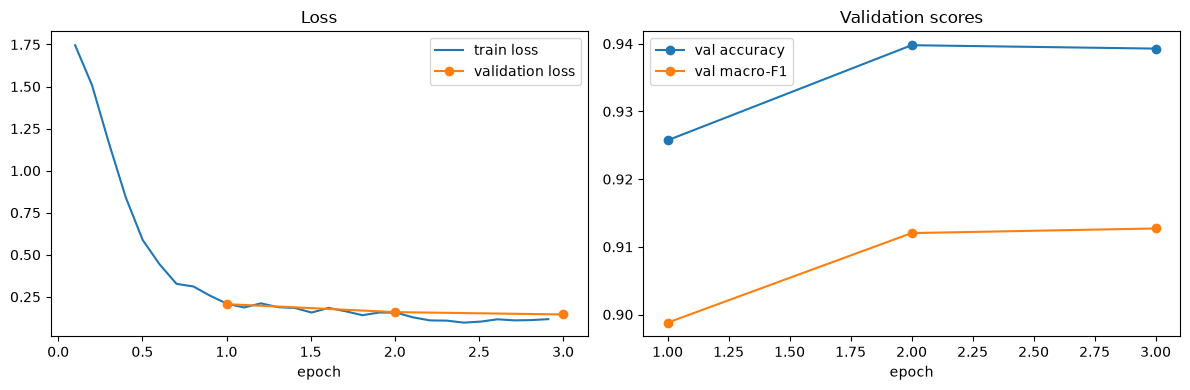

,epoch,eval_loss,eval_accuracy,eval_macro_f1
9,1.0,0.206572,0.925740,0.898801
20,2.0,0.159150,0.939789,0.912031
31,3.0,0.145092,0.939288,0.912713


In [6]:
log = pd.DataFrame(trainer.state.log_history)
train_log = log.dropna(subset=["loss"]) if "loss" in log else pd.DataFrame()
eval_log = log.dropna(subset=["eval_loss"])

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
if len(train_log):
    axes[0].plot(train_log["epoch"], train_log["loss"], label="train loss")
axes[0].plot(eval_log["epoch"], eval_log["eval_loss"], "o-", label="validation loss")
axes[0].set_xlabel("epoch"); axes[0].set_title("Loss"); axes[0].legend()
axes[1].plot(eval_log["epoch"], eval_log["eval_accuracy"], "o-", label="val accuracy")
axes[1].plot(eval_log["epoch"], eval_log["eval_macro_f1"], "o-", label="val macro-F1")
axes[1].set_xlabel("epoch"); axes[1].set_title("Validation scores"); axes[1].legend()
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/distilbert_training_curves.png", dpi=150, bbox_inches="tight")
plt.show()
eval_log[["epoch", "eval_loss", "eval_accuracy", "eval_macro_f1"]]

## Evaluation on the test set
Same metrics as the ML and DL notebooks.

c:\Users\HUAWEI\Downloads\VOXAid-Project-final\.venv\Lib\site-packages\torch\utils\data\dataloader.py:759: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


accuracy: 0.930  macro_precision: 0.903  macro_recall: 0.877  macro_f1: 0.884  weighted_f1: 0.930  roc_auc_ovr: 0.996  top3_accuracy: 0.997  train_time_s: 4654.940
              precision    recall  f1-score   support

       anger      0.928     0.938     0.933       275
        fear      0.875     0.938     0.905       224
         joy      0.955     0.940     0.947       695
        love      0.802     0.893     0.845       159
     sadness      0.969     0.962     0.965       581
    surprise      0.886     0.591     0.709        66

    accuracy                          0.930      2000
   macro avg      0.903     0.877     0.884      2000
weighted avg      0.932     0.930     0.930      2000



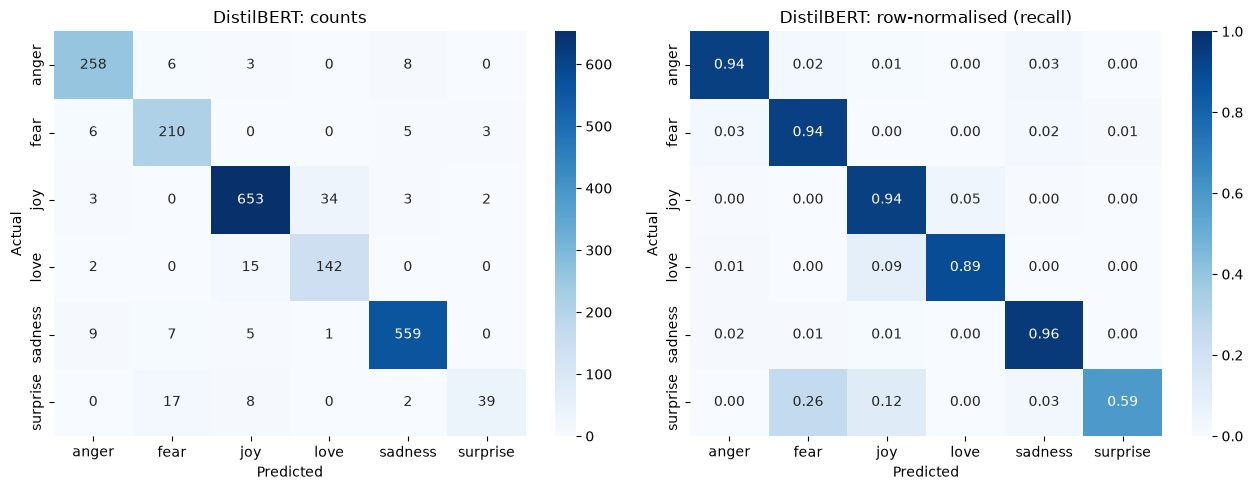

In [7]:
out = trainer.predict(tokenized["test"])
logits, y_test = out.predictions, out.label_ids
y_prob = torch.softmax(torch.tensor(logits), dim=-1).numpy()
y_pred = y_prob.argmax(axis=1)

metrics = {
    "accuracy": accuracy_score(y_test, y_pred),
    "macro_precision": precision_score(y_test, y_pred, average="macro"),
    "macro_recall": recall_score(y_test, y_pred, average="macro"),
    "macro_f1": f1_score(y_test, y_pred, average="macro"),
    "weighted_f1": f1_score(y_test, y_pred, average="weighted"),
    "roc_auc_ovr": roc_auc_score(y_test, y_prob, multi_class="ovr", average="macro"),
    "top3_accuracy": top_k_accuracy_score(y_test, y_prob, k=3, labels=range(len(CLASSES))),
    "train_time_s": train_time,
    "quick_run": QUICK_RUN,
}
report = classification_report(y_test, y_pred, target_names=CLASSES, output_dict=True)
metrics["per_class_f1"] = {c: report[c]["f1-score"] for c in CLASSES}
metrics["per_class_recall"] = {c: report[c]["recall"] for c in CLASSES}

print("  ".join(f"{k}: {v:.3f}" for k, v in metrics.items() if isinstance(v, float)))
print(classification_report(y_test, y_pred, target_names=CLASSES, digits=3))

cm = confusion_matrix(y_test, y_pred)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[0])
axes[0].set_title("DistilBERT: counts")
sns.heatmap(cm / cm.sum(axis=1, keepdims=True), annot=True, fmt=".2f", cmap="Blues",
            xticklabels=CLASSES, yticklabels=CLASSES, ax=axes[1], vmin=0, vmax=1)
axes[1].set_title("DistilBERT: row-normalised (recall)")
for ax in axes:
    ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(f"{PLOT_DIR}/distilbert_confusion_matrix.png", dpi=150, bbox_inches="tight")
plt.show()

## Error analysis

In [8]:
test_df = pd.read_csv(f"{DATA_DIR}/test_clean.csv")
err = test_df[["text", "label"]].copy()
err["predicted"] = [CLASSES[i] for i in y_pred]
wrong = err[err.label != err.predicted]
print(f"{len(wrong)} of {len(err)} misclassified ({len(wrong) / len(err):.1%})\n")
pairs = wrong.groupby(["label", "predicted"]).size().sort_values(ascending=False).head(8)
print(pairs.to_string())
pd.set_option("display.max_colwidth", 120)
for actual, pred in pairs.index[:3]:
    print(f"\n--- actual: {actual}, predicted: {pred} ---")
    for t in wrong[(wrong.label == actual) & (wrong.predicted == pred)]["text"].head(3):
        print("  •", t)

139 of 2000 misclassified (7.0%)

label     predicted
joy       love         34
surprise  fear         17
love      joy          15
sadness   anger         9
surprise  joy           8
anger     sadness       8
sadness   fear          7
fear      anger         6

--- actual: joy, predicted: love ---
  • i feel like i am in paradise kissing those sweet lips make me feel like i dive into a magical world of love
  • i realized what i am passionate about helping women feel accepted and appreciated
  • i could feel his breath on me and smell the sweet scent of him

--- actual: surprise, predicted: fear ---
  • i am right handed however i play billiards left handed naturally so me trying to play right handed feels weird
  • i was so uncomfortable and feeling weird feelings but wasn t sure if they were contractions since i never really felt contractions with jared until they jacked me up with pitocin
  • i just feel are ludicrous and wasting space or so trite they should have looked at the boo

## Save the model and metrics

In [9]:
trainer.save_model(MODEL_OUT)
tokenizer.save_pretrained(MODEL_OUT)

name = "DistilBERT (quick run)" if QUICK_RUN else "DistilBERT"
with open(f"{RESULTS_DIR}/transformer_metrics.json", "w") as f:
    json.dump({name: {k: (v.item() if hasattr(v, "item") else v) for k, v in metrics.items()}}, f, indent=2)
print("saved model to", MODEL_OUT)
print("saved metrics to ../results/transformer_metrics.json")

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

saved model to ../models/transformer/distilbert-emotion
saved metrics to ../results/transformer_metrics.json


### Sanity check: reload and predict new sentences with the app's preprocessing

In [10]:
sys.path.insert(0, "../app")
from voxaid_core import clean_text

tok = AutoTokenizer.from_pretrained(MODEL_OUT)
mdl = AutoModelForSequenceClassification.from_pretrained(MODEL_OUT).eval()
samples = ["I can't believe I finally got the job, I'm so happy!",
           "I'm really worried about my exam tomorrow",
           "Why does everyone keep ignoring me, it's so annoying",
           "I miss my grandmother so much",
           "Wow, I did not expect that at all!",
           "I feel so lucky to have you in my life"]
with torch.no_grad():
    for s in samples:
        p = torch.softmax(mdl(**tok(clean_text(s), return_tensors="pt")).logits[0], -1).numpy()
        top = p.argsort()[::-1][:2]
        print(f"{s:55s} -> {CLASSES[top[0]]:8s} ({p[top[0]]:.2f}), then {CLASSES[top[1]]} ({p[top[1]]:.2f})")

Loading weights:   0%|          | 0/104 [00:00<?, ?it/s]

I can't believe I finally got the job, I'm so happy!    -> joy      (1.00), then sadness (0.00)
I'm really worried about my exam tomorrow               -> fear     (0.91), then anger (0.07)
Why does everyone keep ignoring me, it's so annoying    -> anger    (0.98), then sadness (0.01)
I miss my grandmother so much                           -> sadness  (0.94), then anger (0.02)
Wow, I did not expect that at all!                      -> joy      (0.85), then surprise (0.07)
I feel so lucky to have you in my life                  -> joy      (1.00), then love (0.00)


## Conclusion
- A pre-trained transformer usually gives the best results on CARER (published DistilBERT results are around 92–94% accuracy), because it already understands context and word meaning.
- The cost is size (~255 MB) and speed: it needs PyTorch and is slower than a linear model on CPU. For a free deployment (Streamlit Community Cloud has limited memory) the lighter models are more practical; the app uses DistilBERT automatically if the saved model folder exists.
- See `model_comparison.ipynb` for the final comparison of all models.